In [ ]:
# Task --Price Range Analysis
# Determine the most common price range among all the restaurents.
# calculate the average rating  for each price range. 
# Identify the color that represents the highest average rating among different price ranges.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset
data = pd.read_csv("/home/vansh-kumar/cognifyz Task/Dataset .csv")
print("\nDataset Shape:", data.shape)


Dataset Shape: (9551, 21)


In [10]:
# check required column
required = ["Price range", "Aggregate rating"]

missing = [col for col in required if col not in data.columns]
if missing:
    raise ValueError(f"Missing Columns: {missing}\n"
                     f"Available Columns: {data.columns.tolist()}")
    
# Convert columns to numeric
data["Price range"] = pd.to_numeric(data["Price range"],errors="coerce")
data["Aggregate rating"] = pd.to_numeric(data["Aggregate rating"],errors="coerce")

valid_price = data[data["Price range"].isin([1,2,3,4])].copy()
if valid_price.empty:
    raise ValueError("No valid price range value(1 to 4) found")

In [ ]:
# Distribution Of Price Ranges

price_counts = valid_price["Price range"].value_counts().sort_index()

price_percentage = (price_counts / price_counts.sum()* 100)

# print(price_counts)
# print(price_percentage)

price_summary = pd.DataFrame({"Restaurant_Count": price_counts,
                              "Percentage": price_percentage})

print("\nRestaurant count and percentage by price range:")
print(price_summary.round(2).to_string())

# most common price
most_common = price_counts.idxmax()

print("\nMost common price range:", most_common)
print("Restaurants in this range:", price_counts.max())
print(f"Percentage in this range:"
      f"{price_percentage.loc[most_common]:.2f}%")



Restaurant count and percentage by price range:
             Restaurant_Count  Percentage
Price range                              
1                        4444       46.53
2                        3113       32.59
3                        1408       14.74
4                         586        6.14

Most common price range: 1
Restaurants in this range: 4444
Percentage in this range:46.53%


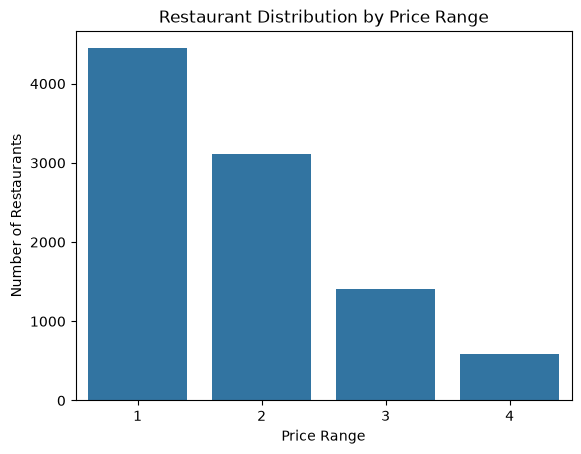

In [21]:
# visualize price Distribution

plt.Figure(figsize=(8,5))

sns.barplot(x=price_counts.index.astype(str),
            y=price_counts.values)

plt.title("Restaurant Distribution by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Number of Restaurants")
plt.show()

In [ ]:
# Rating by price Range

rated = valid_price[valid_price["Aggregate rating"] > 0].copy()

rating_summary = rated.groupby("Price range")["Aggregate rating"].agg(
    Restaurant_Count = "count",
    Average_Rating = "mean",
    Median_Rating = "median",
    Standard_Deviation = "std"
)

print("\nRating statistics by price range:")
print(rating_summary.round(3).to_string())


Rating statistics by price range:
             Restaurant_Count  Average_Rating  Median_Rating  Standard_Deviation
Price range                                                                     
1                        2744           3.239            3.2               0.444
2                        2711           3.377            3.4               0.534
3                        1373           3.777            3.8               0.535
4                         575           3.891            3.9               0.523


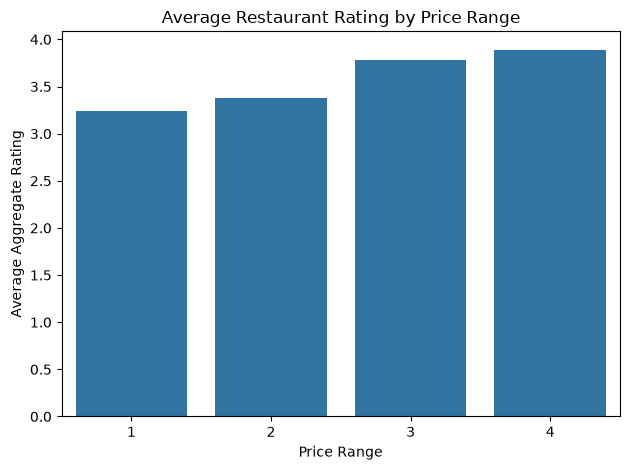

In [25]:
# Average Rating visualization

if not rating_summary.empty:
    plt.Figure(figsize=(8,5))
    
    sns.barplot(x= rating_summary.index.astype(str), 
                y= rating_summary["Average_Rating"].values)
    
    plt.title("Average Restaurant Rating by Price Range")
    plt.xlabel("Price Range")
    plt.ylabel("Average Aggregate Rating")
    plt.tight_layout()
    plt.show()

In [29]:
# Highest Rated price Range

if not rating_summary.empty:
    highest_range = rating_summary["Average_Rating"].idxmax()
    highest_rating = rating_summary.loc[highest_range,"Average_Rating"]
    
    lowest_range = rating_summary["Average_Rating"].idxmin()
    lowest_rating = rating_summary.loc[lowest_range,"Average_Rating"]
    
    print("\nHighest average-rated price range:", highest_range)
    print(f"Average rating: {highest_rating:.3f}")
    
    print("\nLowest average-rated price range:", lowest_range)
    print(f"Average rating: {lowest_rating:.3f}")


Highest average-rated price range: 4
Average rating: 3.891

Lowest average-rated price range: 1
Average rating: 3.239


In [31]:
correlation_data = rating_summary[["Average_Rating"]].copy()

if len(correlation_data) >= 2:
    correlation = correlation_data.index.to_series().corr(correlation_data["Average_Rating"])
    print("\nCorrelation between price category and "
          f"average rating:{correlation:.3f}")
    


Correlation between price category and average rating:0.974
